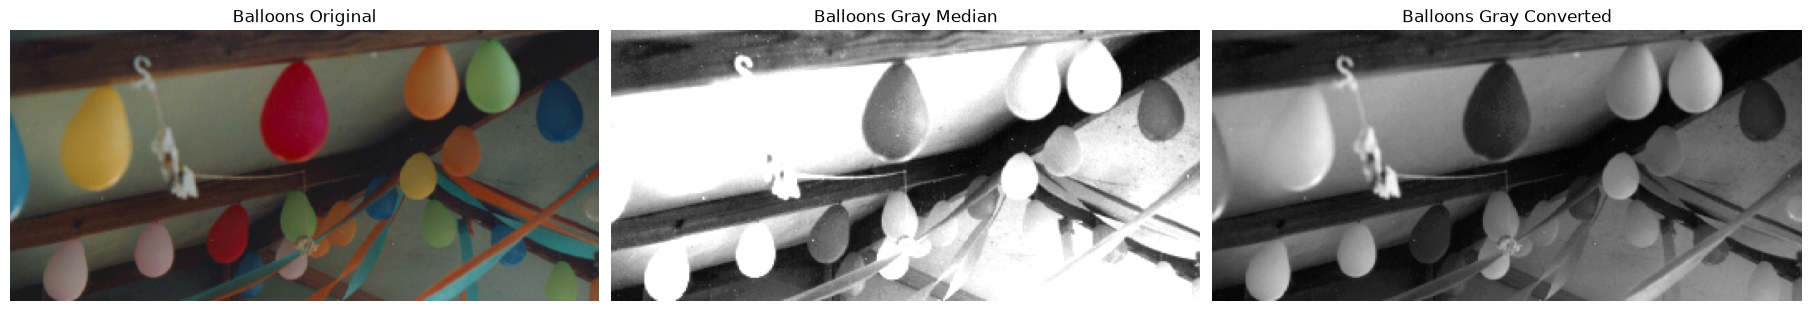

In [15]:
from io import BytesIO
from urllib.request import urlopen
from PIL import Image
import numpy as np

image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/balloons.tif")

with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

original_gray = original.convert("L")

R = original.getchannel("R")
G = original.getchannel("G")    
B = original.getchannel("B")

R_array = np.array(R, dtype=np.float32)
G_array = np.array(G, dtype=np.float32)
B_array = np.array(B, dtype=np.float32)

RGB_images = []

RGB_array = R_array + G_array + B_array

RGB_array_clipped = np.clip(RGB_array, 0, 255).astype(np.uint8)
RGB_images.append(RGB_array_clipped)

RGB_stack = np.array(RGB_images)

median_array = np.median(RGB_stack, axis=0).astype(np.uint8)

final_median_img = Image.fromarray(median_array)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)

axes[0].imshow(original)
axes[0].set_title(f"Balloons Original")
axes[1].imshow(final_median_img, cmap= "gray")
axes[1].set_title(f"Balloons Gray Median",)
axes[2].imshow(original_gray, cmap="gray")
axes[2].set_title(f"Balloons Gray Converted")

for ax in axes:
    ax.axis("off")